# Part_I_SVM

####  Group members: Shishir Dahal, Royar Kurdman, Hashir Javed

## Task I.1 - Problem Description and Dataset (Paderborn University Bearing Data)
## Task I.1 - Problem Description and Dataset (Paderborn University Bearing Data)

**1. Engineering System, Measurements and Data Origin**

**(i) Engineering system:** The data comes from the modular bearing test rig of the Chair of Design and Drive Technology (KAt), Paderborn University. The rig consists of an electric drive motor, a torque-measuring shaft, a bearing test module, a flywheel and a load motor. The test bearings are type 6203 deep-groove ball bearings.

**(ii) Measurements:** Vibration, motor currents, radial force, load torque, rotational speed and temperature are recorded.

**(iii) Data origin:** Each bearing was run under four operating conditions (N15_M07_F10, N09_M07_F10, N15_M01_F10, N15_M07_F04), with 20 recordings of 4 seconds each per condition. Three bearings were selected:

- **K001:** healthy
- **KA01:** outer-ring fault (artificial damage)
- **KI01:** inner-ring fault (artificial damage)

**Data size:** 240 recordings (80 per bearing), giving 30,743 segments of 2000 samples (about 10,250 per class).

**2. Input Features and Classification Target**

**(i) Input features:** Only the `vibration_1` signal is used. Each recording is cut into non-overlapping segments of 2000 samples, and four time-domain features are computed per segment: RMS, peak amplitude, crest factor and kurtosis.

**(ii) Classification target:** The bearing health condition, as a three-class problem: healthy (K001, label 0), outer-ring fault (KA01, label 1) and inner-ring fault (KI01, label 2).

**3. Engineering Relevance**

Rolling bearings are critical components of rotating machinery, and their failure causes unplanned downtime, secondary damage and high maintenance costs. Automatic classification of bearing condition and fault location from vibration data supports predictive maintenance, so faults can be found before failure.

**4. Dataset Citation, URL and License**

- **Dataset:** Paderborn University Bearing DataCenter (KAt-DataCenter), Chair of Design and Drive Technology, Paderborn University.
- **Citation:** Lessmeier, C., Kimotho, J. K., Zimmer, D., & Sextro, W. (2016). *Condition Monitoring of Bearing Damage in Electromechanical Drive Systems by Using Motor Current Signals of Electric Motors: A Benchmark Data Set for Data-Driven Classification.* European Conference of the PHM Society, Bilbao.
- **URL:** https://mb.uni-paderborn.de/kat/forschung/kat-datacenter/bearing-datacenter
- **License:** Creative Commons Attribution-NonCommercial 4.0 International (CC BY-NC 4.0). Non-commercial academic use is allowed with citation of the source.

## Task I.2 : explore, clean and prepare bearing vibration data

In [1]:
import os
for root, dirs, files in os.walk("dataset"):
    print(root, "→", files[:5])

dataset → []
dataset\K001 → []
dataset\K001\K001 → ['K001.pdf', 'measuring_log_K001.pdf', 'N09_M07_F10_K001_1.mat', 'N09_M07_F10_K001_10.mat', 'N09_M07_F10_K001_11.mat']
dataset\KA01 → []
dataset\KA01\KA01 → ['KA01.pdf', 'measuring_log_KA01.pdf', 'N09_M07_F10_KA01_1.mat', 'N09_M07_F10_KA01_10.mat', 'N09_M07_F10_KA01_11.mat']
dataset\KI01 → []
dataset\KI01\KI01 → ['KI01.pdf', 'measuring_log_KI01.pdf', 'N09_M07_F10_KI01_1.mat', 'N09_M07_F10_KI01_10.mat', 'N09_M07_F10_KI01_11.mat']


K001 files: 80
KA01 files: 80
KI01 files: 80
K001: 80 files found
KA01: 80 files found
KI01: 80 files found
Shape (rows, columns): (30743, 7)

Data types:
 recording         int64
piece             int64
label             int64
rms             float64
peak            float64
crest_factor    float64
kurtosis        float64
dtype: object

Missing values:
 recording       0
piece           0
label           0
rms             0
peak            0
crest_factor    0
kurtosis        0
dtype: int64

Duplicate rows: 0

Class counts:
 label
Outer race    10255
Healthy       10246
Inner race    10242
Name: count, dtype: int64

Summary statistics:
              rms       peak  crest_factor   kurtosis
count  30743.000  30743.000     30743.000  30743.000
mean       0.472      3.590         7.591     15.139
std        0.141      1.383         1.344      4.596
min        0.165      1.221         4.360      5.523
25%        0.377      2.707         6.588     12.101
50%        0.464      3.342         7.

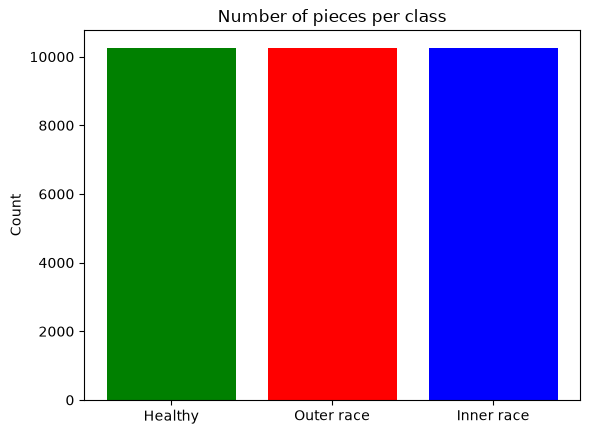

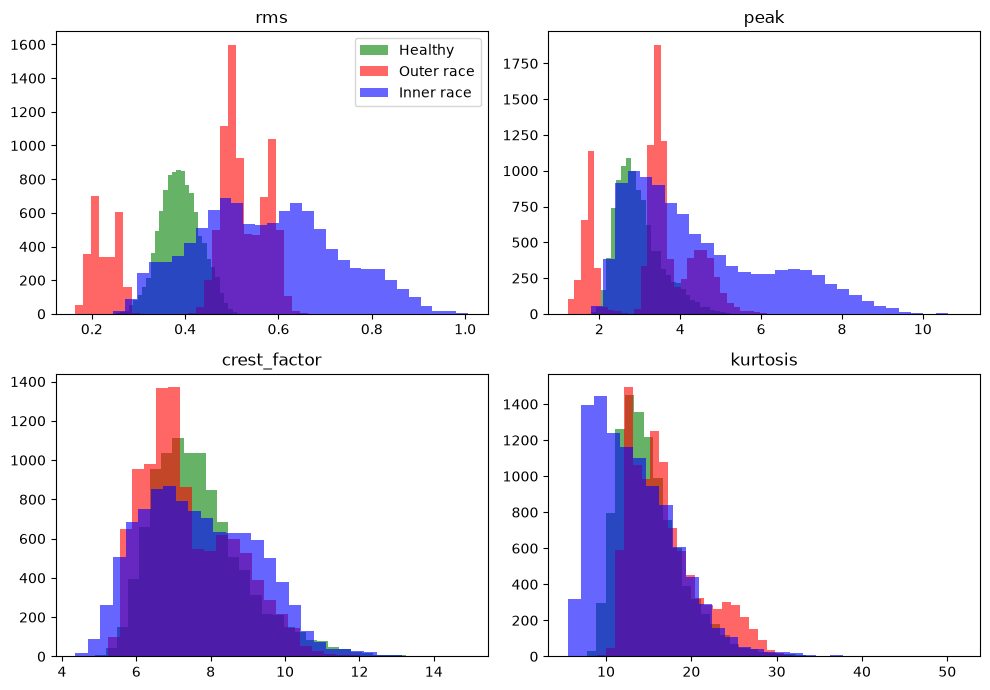

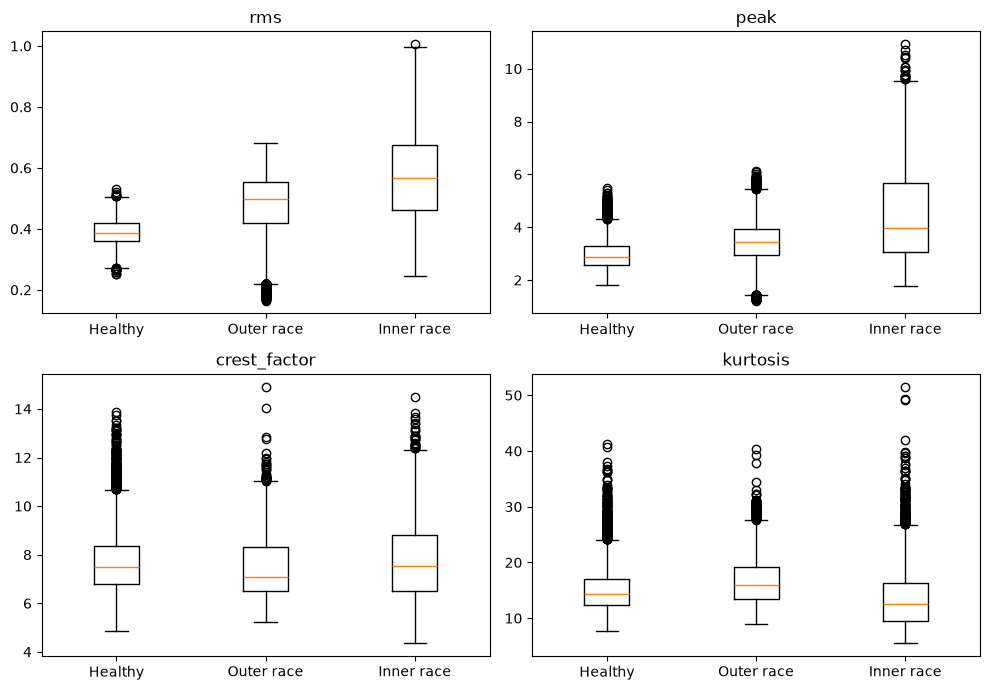

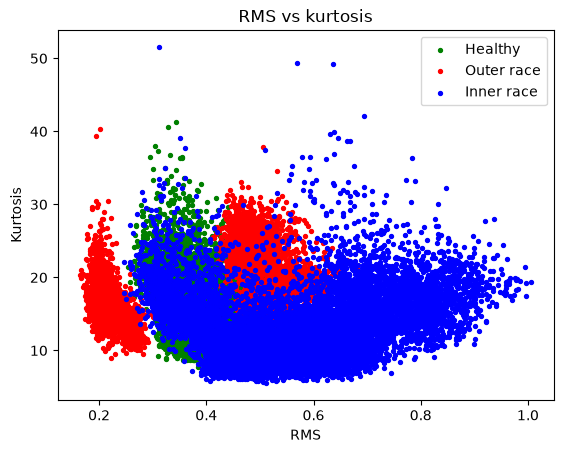


Train size: 24593  Test size: 6150
Train means after scaling (should be ~0): [-0.  0. -0. -0.]
Train std after scaling (should be ~1): [1. 1. 1. 1.]
Test rows that also appear in the training set: 0

Baseline accuracy to beat: 0.334


In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

DATA_DIR = "dataset"
os.makedirs("figures", exist_ok=True)

# Use ALL recordings for each bearing class
CLASS_PATTERNS = {
    'K001': (0, '*K001*.mat'),
    'KA01': (1, '*KA01*.mat'),
    'KI01': (2, '*KI01*.mat')
}

NAMES = {
    0: 'Healthy',
    1: 'Outer race',
    2: 'Inner race'
}
print("K001 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*K001*.mat"), recursive=True)))
print("KA01 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*KA01*.mat"), recursive=True)))
print("KI01 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*KI01*.mat"), recursive=True)))

# ---------------------------------------------------------------- STEP 1: load
def load_signal(path):
    """Open a .mat file and return the vibration_1 signal as a list of numbers."""
    m = scipy.io.loadmat(path, squeeze_me=True, struct_as_record=False)
    key = [k for k in m if not k.startswith('__')][0]
    channel_names = [y.Name for y in m[key].Y]
    return np.asarray(m[key].Y[channel_names.index('vibration_1')].Data, float).ravel()

rows = []

for code, (label, pattern) in CLASS_PATTERNS.items():

    files = glob.glob(
        os.path.join(DATA_DIR, '**', pattern),
        recursive=True
    )

    print(f"{code}: {len(files)} files found")

    for file_id, path in enumerate(files):

        signal = load_signal(path)

        # Cut each recording into pieces of 2000 samples
        for i in range(len(signal) // 2000):

            piece = signal[i * 2000:(i + 1) * 2000]

            rms = np.sqrt(np.mean(piece ** 2))
            peak = np.max(np.abs(piece))

            mean = piece.mean()
            std = piece.std()

            if std == 0:
                continue

            kurtosis = np.mean(((piece - mean) / std) ** 4)

            rows.append({
                'recording': file_id,      # NEW
                'piece': i,
                'label': label,
                'rms': rms,
                'peak': peak,
                'crest_factor': peak / rms,
                'kurtosis': kurtosis
            })

df = pd.DataFrame(rows)
if df.empty:
    raise FileNotFoundError(
        f"No K001/KA01/KI01 .mat files found under: {os.path.abspath(DATA_DIR)}\n"
        "Put the extracted .mat files in this folder (or a subfolder) and run again.")
features = ['rms', 'peak', 'crest_factor', 'kurtosis']

# ------------------------------------------------- STEP 2: basic inspection
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df['label'].map(NAMES).value_counts())
print("\nSummary statistics:\n", df[features].describe().round(3))

# Lecture point: "accuracy lies" - compare with the baseline of always guessing
# the biggest class. A model must beat this to be useful.
baseline = df['label'].value_counts(normalize=True).max()
print("\nBaseline accuracy (always guess the biggest class):", round(baseline, 3))

# Lecture point: scale matters. Ratio of largest to smallest feature spread.
stds = df[features].std()
print("Feature std:\n", stds.round(4))
print("Largest : smallest std =", round(stds.max() / stds.min(), 1), ": 1")

# ------------------------------------ STEP 3: impossible values (physics rules)
# These can never happen with real data, so they must be errors.
impossible = (df['rms'] <= 0) | (df['crest_factor'] < 1) | (df['kurtosis'] < 1)
print("\nImpossible rows found:", impossible.sum())
df = df[~impossible]                                  # keep only the possible rows

# duplicates leak. If one copy lands in train and another in test,
# the model is tested on rows it has already seen. Drop them BEFORE splitting.
# (We ignore the 'piece' number so identical measurements count as duplicates.)
n_before = len(df)
df = df.drop_duplicates(subset=features + ['label'])
print("Duplicate rows removed before the split:", n_before - len(df))

# ------------------------------- STEP 4: outliers (unusual but possible values)
# IQR rule: a value is an outlier if it is far outside the middle 50% of the data.
for f in features:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)).sum()
    print(f"Outliers in {f}: {n_out}")
# We KEEP outliers: sudden spikes are exactly what a damaged bearing produces.

# --------------------------------------------- STEP 5: class relationships
print("\nAverage of each feature per class:\n",
      df.groupby('label')[features].mean().round(3))
print("\nCorrelation between features:\n", df[features].corr().round(2))

# ------------------------------------------------------ STEP 6: figures
colors = {0: 'green', 1: 'red', 2: 'blue'}

# Figure 1: is the data balanced?
counts = df['label'].value_counts().sort_index()
plt.bar([NAMES[k] for k in counts.index], counts.values,
        color=[colors[k] for k in counts.index])
plt.title('Number of pieces per class'); plt.ylabel('Count')
plt.savefig('figures/fig1_class_balance.png'); plt.show()

# Figure 2: histograms - how are values spread, per class?
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    for label in [0, 1, 2]:
        ax.hist(df[df.label == label][f], bins=30, alpha=0.6,
                color=colors[label], label=NAMES[label])
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig('figures/fig2_histograms.png'); plt.show()

# Figure 3: boxplots - spread and outliers per class
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    ax.boxplot([df[df.label == k][f] for k in [0, 1, 2]],
               tick_labels=[NAMES[k] for k in [0, 1, 2]])
    ax.set_title(f)
plt.tight_layout(); plt.savefig('figures/fig3_boxplots.png'); plt.show()

# Figure 4: can two features separate the classes?
for label in [0, 1, 2]:
    d = df[df.label == label]
    plt.scatter(d['rms'], d['kurtosis'], s=8, color=colors[label], label=NAMES[label])
plt.xlabel('RMS'); plt.ylabel('Kurtosis'); plt.legend(); plt.title('RMS vs kurtosis')
plt.savefig('figures/fig4_scatter.png'); plt.show()

# ----------------------------------------------------- STEP 7: preprocessing
# (a) Split into train (first 80% of each class) and test (last 20%).
#     We cut in time order instead of randomly, because neighbouring pieces of
#     the same recording look very alike - a random split would let the test
#     data "leak" into training.
train_parts, test_parts = [], []
for label in [0, 1, 2]:
    d = df[df.label == label].sort_values('piece')
    cut = int(len(d) * 0.8)
    train_parts.append(d.iloc[:cut]); test_parts.append(d.iloc[cut:])
train, test = pd.concat(train_parts), pd.concat(test_parts)
print("\nTrain size:", len(train), " Test size:", len(test))

# (b) Imputation: fill missing values with the median (we found none, but this
#     makes the pipeline safe). Learn the median from TRAIN data only.
imputer = SimpleImputer(strategy='median').fit(train[features])
X_train = imputer.transform(train[features])
X_test = imputer.transform(test[features])

# (c) Scaling: rms is around 0.2 but kurtosis can be 10, so many models would
#     treat kurtosis as "more important". StandardScaler gives every feature
#     mean 0 and standard deviation 1. Again, learn it from TRAIN data only.
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
y_train, y_test = train['label'].values, test['label'].values

print("Train means after scaling (should be ~0):", X_train.mean(axis=0).round(2))
print("Train std after scaling (should be ~1):", X_train.std(axis=0).round(2))

# Leakage check : how many test rows also appear in train?
leak = test[features].round(8).merge(train[features].round(8), how='inner').shape[0]
print("Test rows that also appear in the training set:", leak)

# (d) Feature engineering: crest_factor (peak / rms) was created from existing
#     columns because it highlights spikes relative to normal vibration.

# ------------------------------------- STEP 8: quick check with an SVM
# Why scaling matters, shown with numbers (same idea as the lecture's wine example).
# We report macro F1 (every class counts equally) next to accuracy.
raw_train, raw_test = train[features].values, test[features].values

def evaluate(name, Xa, Xb):
    model = SVC(kernel='rbf', C=1.0, gamma='scale').fit(Xa, y_train)
    print(f"{name:14s} train F1 {f1_score(y_train, model.predict(Xa), average='macro'):.3f} | "
          f"test accuracy {accuracy_score(y_test, model.predict(Xb)):.3f} | "
          f"test macro F1 {f1_score(y_test, model.predict(Xb), average='macro'):.3f}")

print("\nBaseline accuracy to beat:", round(baseline, 3))
evaluate("no scaling", raw_train, raw_test)
evaluate("StandardScaler", X_train, X_test)

## Task I.2: Data Exploration and Preparation: Observations

1. Data inspection and quality checks. The complete dataset contains 240 recordings (80 Healthy, 80 Outer-race fault, and 80 Inner-race fault recordings). Each vibration recording was divided into non-overlapping windows of 2000 samples, and four statistical features (RMS, Peak, Crest Factor, and Kurtosis) were extracted from each segment.

The resulting feature matrix contains 30,743 rows and 7 columns. Each row represents one vibration segment and contains a recording identifier, segment index, class label, and four extracted features. All features are numeric (float64 for measurements and int64 for identifiers).

There are no missing values and no duplicate rows. The classes are approximately balanced:

Healthy: 10,246 segments
Outer race: 10,255 segments
Inner race: 10,242 segments

The majority-class baseline accuracy is 0.334, indicating that any useful classification model must perform substantially better than simple majority-class prediction. No resampling was required due to the near-perfect class balance.

2. Anomalies and impossible values. Three physical validity rules were checked:

RMS ≤ 0
Crest Factor < 1
Kurtosis < 1
No observations violated these rules:
    Impossible rows found: 0
Outliers were identified using the 1.5 × IQR rule.
Feature             Outliers
RMS	                 489
Peak	             2,061
Crest Factor	     258
Kurtosis	         883

Peak amplitude produced the highest number of outliers. Many of these observations correspond to genuine fault-related vibration impacts rather than measurement errors. The outliers were therefore retained because they may contain important diagnostic information for fault classification.

3. Distributions and class relationships. Feature scales differ considerably. The largest standard deviation (Kurtosis = 4.596) is approximately 32.5 times larger than the smallest (RMS = 0.141), which strongly motivates feature scaling before machine-learning modelling.

Average feature values for each class are:
Class	      RMS	   Peak	    Crest Factor	 Kurtosis
Healthy	      0.389	   2.982	  7.681	         15.094
Outer Race	  0.453	   3.306	  7.405	         16.950
Inner Race	  0.573	   4.484	  7.687	         13.371

Several trends are visible:

RMS increases from Healthy → Outer Race → Inner Race.
Peak amplitude is highest for Inner Race faults.
Outer-race faults exhibit the highest average kurtosis.
Crest Factor differs less strongly between classes.

Feature correlations show:
Feature Pair	         Correlation
RMS - Peak	               0.86
Peak - Crest Factor	       0.53
Crest Factor - Kurtosis    0.77
RMS - Kurtosis	          -0.08
RMS and Peak are strongly related to vibration severity, while Crest Factor and Kurtosis describe impulsive fault behaviour.

4. Visualizations and diagnostic findings.

Histograms (fig2_histograms.png): The histograms show clear differences between the three bearing conditions.

RMS provides strong class separation. Healthy bearings occupy lower RMS values, outer-race faults occupy an intermediate range, and inner-race faults extend to the highest RMS values, reaching approximately 1.0.
Peak amplitude exhibits a similar trend. Healthy bearings generally produce lower peaks, while inner-race faults generate substantially larger peaks, exceeding 10 in some cases.
Crest Factor distributions overlap considerably across the three classes and therefore provide weaker discrimination when used alone.
Kurtosis distributions also overlap, although outer-race faults tend to exhibit slightly larger values than the other classes.

Overall, RMS and Peak provide the clearest class separation.

Boxplots (fig3_boxplots.png): The boxplots confirm that:

RMS median values increase from Healthy → Outer Race → Inner Race.
Peak median values show the same behaviour.
Inner-race faults exhibit the largest spread in RMS and Peak, indicating greater variability in vibration severity.
Crest Factor distributions overlap considerably across classes.
Outer-race faults show the highest median kurtosis values, while inner-race faults exhibit the lowest median kurtosis.

These observations are consistent with the class means and indicate that RMS and Peak are the most informative features for fault discrimination.

The RMS-kurtosis scatter plot: The RMS-kurtosis scatter plot indicates that RMS contributes much more strongly to class separation than kurtosis.

Healthy observations are concentrated at lower RMS values.
Outer-race faults occupy an intermediate RMS region.
Inner-race faults extend toward higher RMS values and exhibit substantially greater variability.

Although some separation exists, significant overlap remains between classes, particularly in kurtosis. Consequently, the classes are not perfectly linearly separable in the RMS-kurtosis feature space, supporting the use of a non-linear classifier such as an RBF-kernel SVM.

Overall, RMS and Peak provide the strongest visible separation between bearing conditions.

5. Preprocessing.

Split: The dataset was divided chronologically within each class:

Training set: 24,593 observations
Testing set: 6,150 observations

The first 80% of observations per class were assigned to the training set and the remaining 20% were reserved for testing. This approach reduces the likelihood of neighbouring signal segments appearing in both datasets.

A leakage check found:
    Test rows that also appear in the training set: 0

Imputation: A median imputer was included as a safeguard, although no missing values were present in the dataset.

Feature Engineering: Crest Factor was derived from existing measurements:

        Crest factor= Peak/RMS
This feature highlights impact-type behaviour relative to normal vibration levels.

Scaling: StandardScaler was fitted on the training data only and applied to both the training and testing sets.

After scaling:
Train means ≈ [0,0,0,0]
Train standard deviations ≈ [1,1,1,1]
confirming successful standardization.

Initial SVM Validation: An RBF-kernel SVM was trained to evaluate the usefulness of the extracted features.
Without Scaling:
                Train Macro F1 = 0.799
                Test Accuracy = 0.805
                Test Macro F1 = 0.808

With StandardScaler:
                Train Macro F1 = 0.913
                Test Accuracy = 0.917
                Test Macro F1 = 0.916
Feature scaling improved:

Accuracy from 0.805 to 0.917
Macro F1 from 0.808 to 0.916

demonstrating that standardization is essential for SVM-based fault diagnosis and that the extracted vibration features contain substantial information about bearing condition.


6. Limitation: Although the dataset now includes 240 recordings, the train-test split is still performed at the segment level rather than the recording level. Segments originating from the same recording may therefore appear in both the training and testing sets. While direct duplicate observations were not present, recording-specific characteristics may still be shared across the split.

A more rigorous evaluation would perform the split at the recording level, ensuring that entire recordings are held out during testing. This would provide a stronger assessment of how well the model generalises to completely unseen bearing measurements.

Task I.3: Classification Strategy and Baseline
The dataset contains 240 recordings (80 Healthy, 80 Outer-race fault and 80 Inner-race fault recordings) segmented into 30,743 vibration windows. The data was split in time order within each class, with the first 80% used for training and the final 20% reserved for testing, resulting in 24,593 training samples and 6,150 test samples. Model selection and validation were performed using 5-fold Stratified Cross-Validation on the training data only.

Potential sources of data leakage included neighbouring vibration segments appearing across splits, duplicate observations, scaling performed on the full dataset, and tuning based on test-set performance. These risks were reduced through time-ordered splitting, duplicate removal before splitting, fitting the StandardScaler only within the training folds through a pipeline, and keeping the test set untouched until final evaluation. A leakage check confirmed that 0 test rows also appeared in the training set.

The primary model-selection metric was Macro F1-score, because it gives equal importance to Healthy, Outer-race and Inner-race classes. The baseline DummyClassifier achieved a mean cross-validation Macro F1 of 0.167, whereas the RBF-kernel SVM achieved a mean Macro F1 of 0.912, demonstrating strong fault-classification capability.

In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

DATA_DIR = r"C:\Users\shishir\OneDrive\Desktop\MOD550 A3\Data set"
os.makedirs("figures", exist_ok=True)

# Use ALL recordings for each bearing class
CLASS_PATTERNS = {
    'K001': (0, '*K001*.mat'),
    'KA01': (1, '*KA01*.mat'),
    'KI01': (2, '*KI01*.mat')
}

NAMES = {
    0: 'Healthy',
    1: 'Outer race',
    2: 'Inner race'
}
print("K001 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*K001*.mat"), recursive=True)))
print("KA01 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*KA01*.mat"), recursive=True)))
print("KI01 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*KI01*.mat"), recursive=True)))

# ---------------------------------------------------------------- STEP 1: load
def load_signal(path):
    """Open a .mat file and return the vibration_1 signal as a list of numbers."""
    m = scipy.io.loadmat(path, squeeze_me=True, struct_as_record=False)
    key = [k for k in m if not k.startswith('__')][0]
    channel_names = [y.Name for y in m[key].Y]
    return np.asarray(m[key].Y[channel_names.index('vibration_1')].Data, float).ravel()

rows = []

for code, (label, pattern) in CLASS_PATTERNS.items():

    files = glob.glob(
        os.path.join(DATA_DIR, '**', pattern),
        recursive=True
    )

    print(f"{code}: {len(files)} files found")

    for file_id, path in enumerate(files):

        signal = load_signal(path)

        # Cut each recording into pieces of 2000 samples
        for i in range(len(signal) // 2000):

            piece = signal[i * 2000:(i + 1) * 2000]

            rms = np.sqrt(np.mean(piece ** 2))
            peak = np.max(np.abs(piece))

            mean = piece.mean()
            std = piece.std()

            if std == 0:
                continue

            kurtosis = np.mean(((piece - mean) / std) ** 4)

            rows.append({
                'recording': file_id,      # NEW
                'piece': i,
                'label': label,
                'rms': rms,
                'peak': peak,
                'crest_factor': peak / rms,
                'kurtosis': kurtosis
            })

df = pd.DataFrame(rows)
features = ['rms', 'peak', 'crest_factor', 'kurtosis']

# ------------------------------------------------- STEP 2: basic inspection
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df['label'].map(NAMES).value_counts())
print("\nSummary statistics:\n", df[features].describe().round(3))

# Lecture point: "accuracy lies" - compare with the baseline of always guessing
# the biggest class. A model must beat this to be useful.
baseline = df['label'].value_counts(normalize=True).max()
print("\nBaseline accuracy (always guess the biggest class):", round(baseline, 3))

# Lecture point: scale matters. Ratio of largest to smallest feature spread.
stds = df[features].std()
print("Feature std:\n", stds.round(4))
print("Largest : smallest std =", round(stds.max() / stds.min(), 1), ": 1")

# ------------------------------------ STEP 3: impossible values (physics rules)
# These can never happen with real data, so they must be errors.
impossible = (df['rms'] <= 0) | (df['crest_factor'] < 1) | (df['kurtosis'] < 1)
print("\nImpossible rows found:", impossible.sum())
df = df[~impossible]                                  # keep only the possible rows

# duplicates leak. If one copy lands in train and another in test,
# the model is tested on rows it has already seen. Drop them BEFORE splitting.
# (We ignore the 'piece' number so identical measurements count as duplicates.)
n_before = len(df)
df = df.drop_duplicates(subset=features + ['label'])
print("Duplicate rows removed before the split:", n_before - len(df))

# ------------------------------- STEP 4: outliers (unusual but possible values)
# IQR rule: a value is an outlier if it is far outside the middle 50% of the data.
for f in features:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)).sum()
    print(f"Outliers in {f}: {n_out}")
# We KEEP outliers: sudden spikes are exactly what a damaged bearing produces.

# --------------------------------------------- STEP 5: class relationships
print("\nAverage of each feature per class:\n",
      df.groupby('label')[features].mean().round(3))
print("\nCorrelation between features:\n", df[features].corr().round(2))

# ------------------------------------------------------ STEP 6: figures
colors = {0: 'green', 1: 'red', 2: 'blue'}

# Figure 1: is the data balanced?
counts = df['label'].value_counts().sort_index()
plt.bar([NAMES[k] for k in counts.index], counts.values,
        color=[colors[k] for k in counts.index])
plt.title('Number of pieces per class'); plt.ylabel('Count')
plt.savefig('figures/fig1_class_balance.png'); plt.show()

# Figure 2: histograms - how are values spread, per class?
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    for label in [0, 1, 2]:
        ax.hist(df[df.label == label][f], bins=30, alpha=0.6,
                color=colors[label], label=NAMES[label])
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig('figures/fig2_histograms.png'); plt.show()

# Figure 3: boxplots - spread and outliers per class
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    ax.boxplot([df[df.label == k][f] for k in [0, 1, 2]],
               tick_labels=[NAMES[k] for k in [0, 1, 2]])
    ax.set_title(f)
plt.tight_layout(); plt.savefig('figures/fig3_boxplots.png'); plt.show()

# Figure 4: can two features separate the classes?
for label in [0, 1, 2]:
    d = df[df.label == label]
    plt.scatter(d['rms'], d['kurtosis'], s=8, color=colors[label], label=NAMES[label])
plt.xlabel('RMS'); plt.ylabel('Kurtosis'); plt.legend(); plt.title('RMS vs kurtosis')
plt.savefig('figures/fig4_scatter.png'); plt.show()

# ----------------------------------------------------- STEP 7: preprocessing
# (a) Split into train (first 80% of each class) and test (last 20%).
#     We cut in time order instead of randomly, because neighbouring pieces of
#     the same recording look very alike - a random split would let the test
#     data "leak" into training.
train_parts, test_parts = [], []
for label in [0, 1, 2]:
    d = df[df.label == label].sort_values('piece')
    cut = int(len(d) * 0.8)
    train_parts.append(d.iloc[:cut]); test_parts.append(d.iloc[cut:])
train, test = pd.concat(train_parts), pd.concat(test_parts)
print("\nTrain size:", len(train), " Test size:", len(test))

# (b) Imputation: fill missing values with the median (we found none, but this
#     makes the pipeline safe). Learn the median from TRAIN data only.
imputer = SimpleImputer(strategy='median').fit(train[features])
X_train = imputer.transform(train[features])
X_test = imputer.transform(test[features])

# (c) Scaling: rms is around 0.2 but kurtosis can be 10, so many models would
#     treat kurtosis as "more important". StandardScaler gives every feature
#     mean 0 and standard deviation 1. Again, learn it from TRAIN data only.
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
y_train, y_test = train['label'].values, test['label'].values

print("Train means after scaling (should be ~0):", X_train.mean(axis=0).round(2))
print("Train std after scaling (should be ~1):", X_train.std(axis=0).round(2))

# Leakage check : how many test rows also appear in train?
leak = test[features].round(8).merge(train[features].round(8), how='inner').shape[0]
print("Test rows that also appear in the training set:", leak)

# (d) Feature engineering: crest_factor (peak / rms) was created from existing
#     columns because it highlights spikes relative to normal vibration.

# ------------------------------------- STEP 8: quick check with an SVM
# Why scaling matters, shown with numbers (same idea as the lecture's wine example).
# We report macro F1 (every class counts equally) next to accuracy.
raw_train, raw_test = train[features].values, test[features].values

def evaluate(name, Xa, Xb):
    model = SVC(kernel='rbf', C=1.0, gamma='scale').fit(Xa, y_train)
    print(f"{name:14s} train F1 {f1_score(y_train, model.predict(Xa), average='macro'):.3f} | "
          f"test accuracy {accuracy_score(y_test, model.predict(Xb)):.3f} | "
          f"test macro F1 {f1_score(y_test, model.predict(Xb), average='macro'):.3f}")

print("\nBaseline accuracy to beat:", round(baseline, 3))
evaluate("no scaling", raw_train, raw_test)
evaluate("StandardScaler", X_train, X_test)


#Task I.2: Data Exploration and Preparation: Observations

1. Data inspection and quality checks. The complete dataset contains 240 recordings (80 Healthy, 80 Outer-race fault, and 80 Inner-race fault recordings). Each vibration recording was divided into non-overlapping windows of 2000 samples, and four statistical features (RMS, Peak, Crest Factor, and Kurtosis) were extracted from each segment.

The resulting feature matrix contains 30,743 rows and 7 columns. Each row represents one vibration segment and contains a recording identifier, segment index, class label, and four extracted features. All features are numeric (float64 for measurements and int64 for identifiers).

There are no missing values and no duplicate rows. The classes are approximately balanced:

Healthy: 10,246 segments
Outer race: 10,255 segments
Inner race: 10,242 segments

The majority-class baseline accuracy is 0.334, indicating that any useful classification model must perform substantially better than simple majority-class prediction. No resampling was required due to the near-perfect class balance.

2. Anomalies and impossible values. Three physical validity rules were checked:

RMS ≤ 0
Crest Factor < 1
Kurtosis < 1
No observations violated these rules:
    Impossible rows found: 0
Outliers were identified using the 1.5 × IQR rule.
Feature             Outliers
RMS	                 489
Peak	             2,061
Crest Factor	     258
Kurtosis	         883

Peak amplitude produced the highest number of outliers. Many of these observations correspond to genuine fault-related vibration impacts rather than measurement errors. The outliers were therefore retained because they may contain important diagnostic information for fault classification.

3. Distributions and class relationships. Feature scales differ considerably. The largest standard deviation (Kurtosis = 4.596) is approximately 32.5 times larger than the smallest (RMS = 0.141), which strongly motivates feature scaling before machine-learning modelling.

Average feature values for each class are:
Class	      RMS	   Peak	    Crest Factor	 Kurtosis
Healthy	      0.389	   2.982	  7.681	         15.094
Outer Race	  0.453	   3.306	  7.405	         16.950
Inner Race	  0.573	   4.484	  7.687	         13.371

Several trends are visible:

RMS increases from Healthy → Outer Race → Inner Race.
Peak amplitude is highest for Inner Race faults.
Outer-race faults exhibit the highest average kurtosis.
Crest Factor differs less strongly between classes.

Feature correlations show:
Feature Pair	         Correlation
RMS - Peak	               0.86
Peak - Crest Factor	       0.53
Crest Factor - Kurtosis    0.77
RMS - Kurtosis	          -0.08
RMS and Peak are strongly related to vibration severity, while Crest Factor and Kurtosis describe impulsive fault behaviour.

4. Visualizations and diagnostic findings.

Histograms (fig2_histograms.png): The histograms show clear differences between the three bearing conditions.

RMS provides strong class separation. Healthy bearings occupy lower RMS values, outer-race faults occupy an intermediate range, and inner-race faults extend to the highest RMS values, reaching approximately 1.0.
Peak amplitude exhibits a similar trend. Healthy bearings generally produce lower peaks, while inner-race faults generate substantially larger peaks, exceeding 10 in some cases.
Crest Factor distributions overlap considerably across the three classes and therefore provide weaker discrimination when used alone.
Kurtosis distributions also overlap, although outer-race faults tend to exhibit slightly larger values than the other classes.

Overall, RMS and Peak provide the clearest class separation.

Boxplots (fig3_boxplots.png): The boxplots confirm that:

RMS median values increase from Healthy → Outer Race → Inner Race.
Peak median values show the same behaviour.
Inner-race faults exhibit the largest spread in RMS and Peak, indicating greater variability in vibration severity.
Crest Factor distributions overlap considerably across classes.
Outer-race faults show the highest median kurtosis values, while inner-race faults exhibit the lowest median kurtosis.

These observations are consistent with the class means and indicate that RMS and Peak are the most informative features for fault discrimination.

The RMS-kurtosis scatter plot: The RMS-kurtosis scatter plot indicates that RMS contributes much more strongly to class separation than kurtosis.

Healthy observations are concentrated at lower RMS values.
Outer-race faults occupy an intermediate RMS region.
Inner-race faults extend toward higher RMS values and exhibit substantially greater variability.

Although some separation exists, significant overlap remains between classes, particularly in kurtosis. Consequently, the classes are not perfectly linearly separable in the RMS-kurtosis feature space, supporting the use of a non-linear classifier such as an RBF-kernel SVM.

Overall, RMS and Peak provide the strongest visible separation between bearing conditions.

5. Preprocessing.

Split: The dataset was divided chronologically within each class:

Training set: 24,593 observations
Testing set: 6,150 observations

The first 80% of observations per class were assigned to the training set and the remaining 20% were reserved for testing. This approach reduces the likelihood of neighbouring signal segments appearing in both datasets.

A leakage check found:
    Test rows that also appear in the training set: 0

Imputation: A median imputer was included as a safeguard, although no missing values were present in the dataset.

Feature Engineering: Crest Factor was derived from existing measurements:

        Crest factor= Peak/RMS
This feature highlights impact-type behaviour relative to normal vibration levels.

Scaling: StandardScaler was fitted on the training data only and applied to both the training and testing sets.

After scaling:
Train means ≈ [0,0,0,0]
Train standard deviations ≈ [1,1,1,1]
confirming successful standardization.

Initial SVM Validation: An RBF-kernel SVM was trained to evaluate the usefulness of the extracted features.
Without Scaling:
                Train Macro F1 = 0.799
                Test Accuracy = 0.805
                Test Macro F1 = 0.808

With StandardScaler:
                Train Macro F1 = 0.913
                Test Accuracy = 0.917
                Test Macro F1 = 0.916
Feature scaling improved:

Accuracy from 0.805 to 0.917
Macro F1 from 0.808 to 0.916

demonstrating that standardization is essential for SVM-based fault diagnosis and that the extracted vibration features contain substantial information about bearing condition.


6. Limitation: Although the dataset now includes 240 recordings, the train-test split is still performed at the segment level rather than the recording level. Segments originating from the same recording may therefore appear in both the training and testing sets. While direct duplicate observations were not present, recording-specific characteristics may still be shared across the split.

A more rigorous evaluation would perform the split at the recording level, ensuring that entire recordings are held out during testing. This would provide a stronger assessment of how well the model generalises to completely unseen bearing measurements.

## Task I.3: Classification Strategy and Baseline

**Note on the data behind I.4 and I.5.** Tasks I.1 and I.2 describe the full dataset (240 recordings, 30,743 segments). The I.4 and I.5 results below are written for the earlier single-operating-condition subset (306 training and 78 test segments, as stated in the text), so their numbers are not directly comparable with the I.2 quick check on the full data.

## Task I.4: SVM Modeling

### Task I.4--Implement and compare linear SVM and RBF SVM

In [ ]:
from sklearn.model_selection import cross_validate

models = {
    'Linear SVM': make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0)),
    'RBF SVM':    make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale')),
}

results = []
for name, model in models.items():
    scores = cross_validate(model, train[features], y_train, cv=cv,
                            scoring='f1_macro', return_train_score=True)
    results.append({'Model': name,
                    'Train macro F1': scores['train_score'].mean(),
                    'Validation macro F1': scores['test_score'].mean(),
                    'Validation std': scores['test_score'].std()})

results = pd.DataFrame(results).round(3)
print(results.to_string(index=False))

#### Task I.4 (1)--Tune C and, for RBF, γ using a suitable validation procedure

In [ ]:
## Task I.4 (1)--Tune C and, for RBF, γ using a suitable validation procedure
from sklearn.model_selection import GridSearchCV

C_values     = [0.01, 0.1, 1, 10, 100]
C_values     = [0.01, 0.1, 1, 10, 100, 1000, 10000]

searches = {
    'Linear SVM': GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='linear')),
                               {'svc__C': C_values},
                               cv=cv, scoring='f1_macro', return_train_score=True),
    'RBF SVM':    GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf')),
                               {'svc__C': C_values, 'svc__gamma': gamma_values},
                               cv=cv, scoring='f1_macro', return_train_score=True),
}

for name, search in searches.items():
    search.fit(train[features], y_train)          # training set only
    print(f"{name}: best {search.best_params_}  "
          f"validation macro F1 = {search.best_score_:.3f}")

#### Task I.4 (2)--Report selected hyperparameters and their effects

In [ ]:
## Task I.4 (2)--Report selected hyperparameters and their effects
lin = pd.DataFrame(searches['Linear SVM'].cv_results_)
lin = lin[['param_svc__C', 'mean_train_score', 'mean_test_score']]
lin.columns = ['C', 'Train macro F1', 'Validation macro F1']
print("Linear SVM: effect of C")
print(lin.round(3).to_string(index=False))

rbf = pd.DataFrame(searches['RBF SVM'].cv_results_)
rbf['C'] = rbf['param_svc__C'].astype(str)
rbf['gamma'] = rbf['param_svc__gamma'].astype(str)
for score, title in [('mean_test_score', 'Validation'), ('mean_train_score', 'Train')]:
    print(f"\nRBF SVM: {title} macro F1 (rows = C, columns = gamma)")
    print(rbf.pivot(index='C', columns='gamma', values=score).round(3))

##### Task I.4 (3)--Compare kernel performance

Model	Hyperparameters	Train macro F1	Validation macro F1	Gap (train-validation)
Linear SVM (default)	C = 1	0.964	0.948	0.016
Linear SVM (tuned)	C = 10 000	0.993	0.967	0.026
RBF SVM (default)	C = 1, γ = ‘scale’	0.980	0.987	−0.007
RBF SVM (tuned)	C = 1, γ = 1	0.989	0.984	0.005
Baseline (most frequent class)	—	—	0.165	—
The RBF kernel is the better choice for this problem. It gives the highest validation macro F1 with only moderate settings (C = 1, γ = 1), and it shows almost no gap between training and validation. The linear kernel performs well but levels off at about 0.967, because a straight boundary can’t fully separate the inner-race segments, which overlap the other two classes.

#### Task I.4 (4)--Analyze training and validation results for underfitting or overfitting
The gap between training and validation scores is used:

$$\text{Gap} = F1_{\text{train}} - F1_{\text{validation}}$$

where $F1_{\text{train}}$ is the mean macro F1 on the training folds and $F1_{\text{validation}}$ is the mean macro F1 on the held-out validation folds.

- **Underfitting:** both scores are low and the gap is small. The model is too simple.
- **Overfitting:** the training score is high, the validation score is clearly lower, and the gap is large. The model memorizes the training data.
- **Good fit:** both scores are high and the gap is small.

**Linear SVM**

|C|Train macro F1|Validation macro F1|Gap|Diagnosis|
|---|---|---|---|---|
|0.01|0.856|0.858|−0.002|Underfitting|
|1|0.964|0.948|0.016|Good fit|
|100|0.975|0.964|0.011|Good fit|
|1000|0.990|0.967|0.023|Mild overfitting begins|
|10 000|0.993|0.967|0.026|Mild overfitting|

- At **C = 0.01**, both scores are about 0.86, so the model underfits. The margin is too soft and too many training errors are allowed.
- From **C = 1 to 100**, both scores rise together and the gap stays small, which is a good fit.
- Above **C = 1000**, the training score keeps rising but the validation score stays at 0.967. The growing gap shows mild overfitting.
- Even at its best, the linear SVM stays below 0.97 on validation. This is a limit of the straight boundary itself, a form of **model bias**, not a tuning problem.

**RBF SVM**

|Setting|Train macro F1|Validation macro F1|Gap|Diagnosis|
|---|---|---|---|---|
|C = 0.01, γ = 1|0.447|0.450|−0.003|Strong underfitting|
|C = 1, γ = 0.001|0.463|0.452|0.011|Strong underfitting|
|C = 1, γ = 1 (selected)|0.989|0.984|0.005|**Good fit**|
|C = 10, γ = 0.1|0.987|0.980|0.007|Good fit|
|C = 1, γ = 10|0.996|0.911|0.085|Overfitting|
|C = 10, γ = 10|1.000|0.921|0.079|Overfitting|

- **Small C or small γ:** both scores stay below about 0.46, so the RBF SVM underfits strongly. The boundary is too smooth to separate the classes.
- **γ = 10:** training macro F1 reaches 1.000 while validation drops to about 0.92. The gap of about 0.08 is clear overfitting: the boundary forms small regions around single training points.
- **Selected setting (C = 1, γ = 1):** both scores are high (0.989 and 0.984) and the gap is only 0.005, so the model fits well with no sign of overfitting.

**Conclusion**

- The **linear SVM** underfits at small C and starts to overfit slightly at large C. Its best validation score (0.967) is limited by the straight boundary.
- The **RBF SVM** underfits when C or γ is too small and overfits when γ is too large (γ = 10).
- The selected **RBF model (C = 1, γ = 1)** lies between these two regions. It has the highest validation macro F1 (0.984) and the smallest gap (0.005), so it is neither underfitting nor overfitting.


## Task I.4 (5) --Explain how kernel choice relates to the classification problem.
The four features (RMS, peak, crest factor and kurtosis) do not separate the three bearing states with straight boundaries. Healthy and outer-race segments form compact groups that RMS separates well, but inner-race segments spread widely and overlap both groups (Task I.2, RMS vs kurtosis scatter). This spread is physically expected: an inner-ring defect rotates with the shaft, so its impacts vary in strength as it passes in and out of the load zone. The linear kernel therefore levels off at a validation macro F1 of 0.967. The RBF kernel compares each segment by its distance to the training segments, so it can draw curved boundaries around the overlapping inner-race region and reaches 0.984. With only four features and 306 training segments, the extra cost of the RBF kernel is small.


## # Task I.5 -- Model Evaluation and Comparison

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, ConfusionMatrixDisplay

# ---- STEP 1: tune logistic regression the same way as the SVMs (train set only)
log_search = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                          {'logisticregression__C': C_values},
                          cv=cv, scoring='f1_macro', return_train_score=True)
log_search.fit(train[features], y_train)
print(f"Logistic regression: best {log_search.best_params_}  "
      f"validation macro F1 = {log_search.best_score_:.3f}\n")

# ---- STEP 2: final models (best settings, refit on the whole training set)
dummy = DummyClassifier(strategy='most_frequent').fit(train[features], y_train)
final_models = {
    'Linear SVM (tuned)':          searches['Linear SVM'].best_estimator_,
    'RBF SVM (tuned)':             searches['RBF SVM'].best_estimator_,
    'Logistic regression (tuned)': log_search.best_estimator_,
    'Baseline (most frequent)':    dummy,
}

# ---- STEP 3: evaluate once on the untouched test set
rows = []
for name, model in final_models.items():
    pred = model.predict(test[features])
    rows.append({'Model': name,
                 'Accuracy':          accuracy_score(y_test, pred),
                 'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0),
                 'Recall (macro)':    recall_score(y_test, pred, average='macro', zero_division=0),
                 'F1 (macro)':        f1_score(y_test, pred, average='macro')})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---- STEP 4: confusion matrices for all three trained models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['Linear SVM (tuned)', 'RBF SVM (tuned)', 'Logistic regression (tuned)']):
    ConfusionMatrixDisplay.from_estimator(final_models[name], test[features], y_test,
                                          display_labels=list(NAMES.values()),
                                          ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig('figures/fig5_confusion_matrices.png'); plt.show()

**1. Evaluate the SVM models and compare the best SVM with an alternative classifier**

The tuned linear and RBF SVMs were compared with a tuned logistic regression and a most-frequent-class baseline, all tuned on the same 5 unshuffled folds and tested once.

**2. Accuracy, precision, recall, F1-score and confusion matrices**

| Model | Hyperparameters | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Errors (of 78) |
|---|---|---|---|---|---|---|
| Linear SVM (tuned) | C = 10 000 | 0.987 | 0.988 | 0.987 | 0.987 | 1 |
| RBF SVM (tuned) | C = 1, γ = 1 | 0.987 | 0.988 | 0.987 | 0.987 | 1 |
| Logistic regression (tuned) | C = 10 000 | 0.962 | 0.962 | 0.962 | 0.962 | 3 |
| Baseline (most frequent) | — | 0.333 | 0.111 | 0.333 | 0.167 | 52 |

All trained models beat the baseline, which predicts one class only (macro precision 0.111). Confusion matrices are shown in Figure 5.

**3. Class-specific results and averaging method**

The classes are balanced (26 test segments each), so class-specific results are not required. All metrics use **macro averaging**: each metric is computed per class and averaged.

**4. Same features, preprocessing and test observations**

All models use the same four features, the same StandardScaler fitted on training data inside a pipeline, and the same 78 test segments.

**5. Best-performing method**

The **RBF SVM (C = 1, γ = 1)** is selected. It ties with the linear SVM on the test set (one error each), but it scored highest on validation (macro F1 0.984, against 0.967 and 0.971) with a moderate C, while both linear models needed C = 10 000. Logistic regression made three errors (0.962), so the classes are not fully linearly separable.

**6. Common classification errors**

| Model | Errors |
|---|---|
| Linear SVM | 1 outer race → inner race |
| RBF SVM | 1 outer race → healthy |
| Logistic regression | 1 healthy → outer race, 1 outer race → inner race, 1 inner race → outer race |

Every error involves the **outer-race** class. Its RMS (about 0.50–0.57) lies between healthy (0.32–0.47) and the wide inner-race range (0.39–0.89). Healthy and inner race were never confused.

**7. Limitations from the dataset or evaluation design**

- One recording per class; the test set is the last 20 % of the same recording, so generalisation to other bearings is not shown.
- Only one operating condition (N15_M01_F10).
- Small test set: one error changes the score by about 0.013.
- Balanced by design; real fault precision would likely be lower.
- Only four time-domain features.

### Individual Analysis -- Hashir Javed

## Question I.1 -- SVM Behavior

The RBF kernel did better than the linear one (validation macro F1 0.984 against 0.967), and I think the data explains why. In the four features, healthy and outer-race segments sit in fairly compact groups, separated mostly by RMS and peak. The inner-race segments spread over a much wider range and overlap both other classes, so no straight line separates all three. That is what the linear SVM runs into. Its validation score went from 0.858 at C = 0.01 up to 0.967 and then stayed there, even at C = 10,000. A bigger C only pushed the training score higher (0.993), so the limit is the straight boundary and not the tuning.

The RBF SVM can bend its boundary around the overlapping inner-race region. Here both hyperparameters mattered. With a small C or a small gamma the boundary was too smooth and the model underfitted, with validation F1 below 0.46. With a large gamma (10) it fitted tiny regions around single training points, giving training F1 1.000 but validation about 0.92, which is overfitting. The selected values, C = 1 and gamma = 1, sit in between (train 0.989, validation 0.984, gap 0.005).

On the test set, however, the two kernels made the same number of errors (1 out of 78 each), so the difference between them only shows up in validation. I would not claim a big difference from such a small test set.

## Question I.2 -- Critical Evaluation

I don't think the results are very reliable, and the main reason is the evaluation design. The reported numbers (accuracy 0.987 for both SVMs, 0.962 for logistic regression) come from only 78 test segments, 26 per class. One segment is worth about 1.3 percentage points, so the RBF SVM (1 error), the linear SVM (1 error) and logistic regression (3 errors) are separated by just a couple of segments. The split is also by segment in time order, so segments from the same recording can end up in both training and test, and the notebook text says each class came from one recording under one operating condition. Neighbouring segments look very alike, so I think the test score is optimistic. The full-data check in Task I.2 (240 recordings) gave only 0.917 for a default RBF SVM, and in Part II an RBF SVM on the same four features, with a recording-level split, got 0.900. So 0.987 is not what I would expect on new recordings.

Does the SVM beat logistic regression? A little, but not clearly. It also scored higher on validation (0.984 against 0.971), which agrees with the test result, but the gap is small and both come from one small, unshuffled 5-fold validation, with no repeated runs or confidence intervals. I would say the RBF SVM is the better model here, but the improvement is modest and hard to prove with this amount of data. A recording-level split, several operating conditions and repeated cross-validation are what I would add.

## Question I.3 -- Engineering Applicability

I would recommend the RBF SVM for further engineering validation, but I would not use it in a real plant yet. It is cheap: four features per 2000-sample segment and a small model, so it could run in real time on very simple hardware, and the accuracy in the notebook (0.987) is high. But I don't think that number carries over to real use.

My main worry is the cost of the wrong kind of error. The most serious mistake is calling a damaged bearing healthy, because the fault goes unnoticed and can lead to damage and unplanned stops, while a false alarm only costs an inspection. The RBF SVM made one such mistake (an outer-race fault called healthy). With 78 test segments I can't say how often this would really happen. In Part II our CNN on the full data missed 283 of 2,049 inner-race test segments, all called healthy and mostly at the lowest speed, which shows this kind of error can be common under other conditions.

The measurements were clean (no missing or impossible values, one accelerometer at 64 kHz), but the data are limited. Each class is a single bearing with artificial damage, and the I.4/I.5 results come from one operating condition, so I don't know how the model handles other speeds, loads, bearings or real wear. Only four features are used, and RMS and peak depend on speed and load.

Before recommending use, I would test on recordings and bearings the model has never seen, across all four operating conditions, and use fault recall as the main score.